## Membaca data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, LeaveOneOut, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

PATH = '17_Jumlah_Produksi_Cengkeh.xlsx'
ws = openpyxl.load_workbook(PATH).active
rows = [r[:7] for r in ws.iter_rows(min_row=11, max_row=48, values_only=True)]
df = pd.DataFrame(rows, columns=['No', 'Provinsi', '2020', '2021', '2022', '2023', '2024'])
df = df.replace('-', np.nan)
for c in ['2020', '2021', '2022', '2023', '2024']:
    df[c] = pd.to_numeric(df[c])
print(df.shape)
df.head()

(38, 7)


,No,Provinsi,2020,2021,2022,2023,2024
0,1,Aceh,5661.206,5727.41000,5738.72000,5916.65,5542.0
1,2,Sumatera Utara,1814.000,2028.69000,2247.00000,1935.97,2008.0
2,3,Sumatera Barat,2120.916,2244.31809,2240.38688,2326.02,2428.0
3,4,Riau,0.000,0.00000,0.00000,0.00,NaN
4,5,Jambi,28.000,28.00000,29.00000,33.00,27.0


## EDA

In [2]:
print(df.dtypes, '\n')
print('Missing value per kolom:'); print(df.isna().sum(), '\n')
print('Total sel kosong:', df.isna().sum().sum(), 'dari', 38*5, 'sel nilai produksi')
print(df[df.isna().any(axis=1)])

No            int64
Provinsi     object
2020        float64
2021        float64
2022        float64
2023        float64
2024        float64
dtype: object 

Missing value per kolom:
No          0
Provinsi    0
2020        0
2021        0
2022        0
2023        0
2024        3
dtype: int64 

Total sel kosong: 3 dari 190 sel nilai produksi
    No           Provinsi  2020  2021  2022  2023  2024
3    4               Riau   0.0   0.0   0.0   0.0   NaN
10  11        DKI Jakarta   0.0   0.0   0.0   0.0   NaN
20  21  Kalimantan Tengah   0.0   0.0   0.0   0.0   NaN


In [3]:
yrs = ['2020', '2021', '2022', '2023', '2024']
print(df[yrs].describe().round(1))
print('\nMean vs median 2024:', round(df['2024'].mean(),1), 'vs', df['2024'].median())
print('Skewness:'); print(df[yrs].skew().round(2))
print('\nJumlah nilai 0 per tahun:'); print((df[yrs]==0).sum())

          2020     2021     2022     2023     2024
count     38.0     38.0     38.0     38.0     35.0
mean    3841.7   3572.4   3608.5   3510.7   4494.9
std     5980.4   6021.1   6190.5   6229.7   7169.9
min        0.0      0.0      0.0      0.0      0.0
25%       13.2      8.8      8.3     13.1     24.0
50%      993.0    504.4    471.4    502.0   1251.0
75%     4256.4   3997.8   3930.5   3886.3   5042.5
max    20694.5  21854.3  22219.9  22768.5  25833.0

Mean vs median 2024: 4494.9 vs 1251.0
Skewness:
2020    1.84
2021    2.16
2022    2.16
2023    2.28
2024    1.93
dtype: float64

Jumlah nilai 0 per tahun:
2020    8
2021    7
2022    7
2023    4
2024    1
dtype: int64


In [4]:
# Outlier dengan IQR per tahun
for c in yrs:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    hi = q3 + 1.5*iqr
    print(c, 'batas atas =', round(hi,1), '->', df.loc[df[c] > hi, 'Provinsi'].tolist())

2020 batas atas = 10621.3 -> ['Jawa Timur', 'Sulawesi Tengah', 'Sulawesi Selatan', 'Sulawesi Tenggara', 'Maluku']
2021 batas atas = 9981.4 -> ['Jawa Timur', 'Sulawesi Tengah', 'Sulawesi Selatan', 'Maluku']
2022 batas atas = 9813.9 -> ['Jawa Timur', 'Sulawesi Tengah', 'Sulawesi Selatan', 'Sulawesi Tenggara', 'Maluku']
2023 batas atas = 9696.2 -> ['Sulawesi Tengah', 'Sulawesi Selatan', 'Sulawesi Tenggara', 'Maluku']
2024 batas atas = 12570.2 -> ['Sulawesi Utara', 'Sulawesi Tengah', 'Sulawesi Selatan', 'Sulawesi Tenggara', 'Maluku']


In [5]:
# Cek konsistensi deret waktu: perubahan tahunan per provinsi (hanya provinsi yang produksinya > 100 ton)
g = df.set_index('Provinsi')[yrs].astype(float)
yoy = g.pct_change(axis=1).drop(columns='2020') * 100
mask = (g[yrs[:-1]].min(axis=1) > 0)
print(yoy[mask].abs().max(axis=1).sort_values(ascending=False).head(5).round(0))
print(g.loc['Sulawesi Utara'])

Provinsi
Sulawesi Utara               6835.0
Kepulauan Bangka Belitung     194.0
Kalimantan Utara               97.0
Papua Barat                    82.0
Sumatera Selatan               66.0
dtype: float64
2020    10109.80
2021      140.81
2022       19.21
2023      194.06
2024    13458.00
Name: Sulawesi Utara, dtype: float64


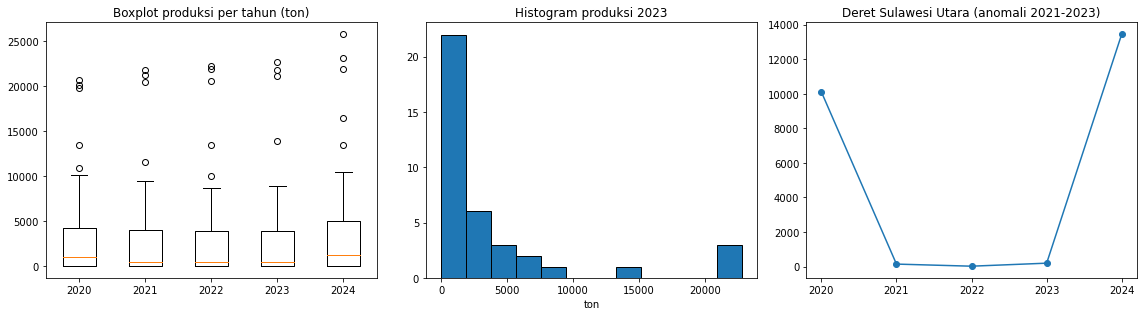

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# Boxplot: beri label sumbu-x secara terpisah (kompatibel semua versi)
ax[0].boxplot([df[c].dropna() for c in yrs])
ax[0].set_xticklabels(yrs)
ax[0].set_title('Boxplot produksi per tahun (ton)')

ax[1].hist(df['2023'], bins=12, edgecolor='k')
ax[1].set_title('Histogram produksi 2023')
ax[1].set_xlabel('ton')

sut = g.loc['Sulawesi Utara']
ax[2].plot(yrs, sut.values, marker='o')
ax[2].set_title('Deret Sulawesi Utara (anomali 2021-2023)')

plt.tight_layout()
plt.savefig('eda.png', dpi=130)
plt.show()

Korelasi 2023 vs 2024 (data mentah): 0.945


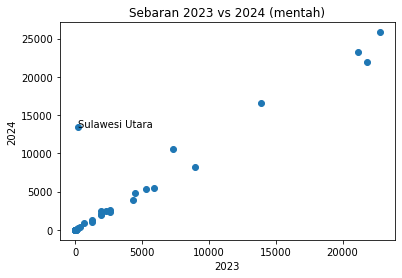

In [7]:
print('Korelasi 2023 vs 2024 (data mentah):', round(df[['2023','2024']].corr().iloc[0,1], 4))
plt.scatter(df['2023'], df['2024']); plt.xlabel('2023'); plt.ylabel('2024'); plt.title('Sebaran 2023 vs 2024 (mentah)')
plt.annotate('Sulawesi Utara', (194.06, 13458)); 
plt.show()

## Preprocessing

In [8]:
clean = df.copy()
# 1) missing value -> 0 (produksi nol berturut-turut 4 tahun)
clean['2024'] = clean['2024'].fillna(0)

# 2) anomali Sulawesi Utara -> interpolasi linier 2020..2024
i = clean.index[clean['Provinsi'] == 'Sulawesi Utara'][0]
a, b = clean.loc[i, '2020'], clean.loc[i, '2024']
for k, y in enumerate(['2021', '2022', '2023'], start=1):
    clean.loc[i, y] = a + (b - a) * k / 4
print(clean.loc[i, yrs])
print('\nSisa missing:', clean[yrs].isna().sum().sum())
print('Korelasi 2023 vs 2024 (setelah dibersihkan):', round(clean[['2023','2024']].corr().iloc[0,1], 4))

2020     10109.8
2021    10946.85
2022     11783.9
2023    12620.95
2024     13458.0
Name: 24, dtype: object

Sisa missing: 0
Korelasi 2023 vs 2024 (setelah dibersihkan): 0.9953


## Pemodelan: Regresi Linier sederhana (y = produksi 2024, x = produksi 2023)

In [9]:
def evaluasi(nama, y_true, y_pred):
    wape = np.abs(y_true - y_pred).sum() / y_true.sum() * 100
    print(f'{nama:<28} R2={r2_score(y_true,y_pred):.4f}  MAE={mean_absolute_error(y_true,y_pred):8.1f} ton  '
          f'RMSE={mean_squared_error(y_true,y_pred)**.5:8.1f} ton  WAPE={wape:5.1f}%')

X = clean[['2023']].values; y = clean['2024'].values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_tr, y_tr)
print('Koefisien (b1) =', round(model.coef_[0], 4), '| Intersep (b0) =', round(model.intercept_, 2))
print('Persamaan: y = %.2f + %.4f * x' % (model.intercept_, model.coef_[0]))
print(len(y_tr), 'data latih,', len(y_te), 'data uji\n')
evaluasi('Data latih', y_tr, model.predict(X_tr))
evaluasi('Data uji', y_te, model.predict(X_te))
evaluasi('Baseline (2024 = 2023), uji', y_te, X_te.ravel())

Koefisien (b1) = 1.1126 | Intersep (b0) = -112.91
Persamaan: y = -112.91 + 1.1126 * x
30 data latih, 8 data uji

Data latih                   R2=0.9865  MAE=   343.4 ton  RMSE=   623.1 ton  WAPE= 10.9%
Data uji                     R2=0.9923  MAE=   525.8 ton  RMSE=   881.7 ton  WAPE=  6.7%
Baseline (2024 = 2023), uji  R2=0.9864  MAE=   622.1 ton  RMSE=  1170.1 ton  WAPE=  7.9%


In [10]:
# Validasi silang leave-one-out: dengan 38 data, satu kali split 80/20 mudah menyesatkan
loo = cross_val_predict(LinearRegression(), X, y, cv=LeaveOneOut())
evaluasi('LOO-CV model', y, loo)
evaluasi('LOO baseline naif', y, X.ravel())

LOO-CV model                 R2=0.9880  MAE=   382.0 ton  RMSE=   753.2 ton  WAPE=  9.2%
LOO baseline naif            R2=0.9819  MAE=   404.8 ton  RMSE=   928.0 ton  WAPE=  9.8%


In [11]:
# Dampak pembersihan data: model yang sama pada data mentah (Sulut 2023 = 194 ton, 3 sel kosong = 0)
raw = df.copy(); raw['2024'] = raw['2024'].fillna(0)
m_raw = LinearRegression().fit(raw[['2023']], raw['2024'])
evaluasi('Tanpa koreksi Sulut', raw['2024'].values, m_raw.predict(raw[['2023']]))
m_cl = LinearRegression().fit(X, y)
evaluasi('Dengan koreksi Sulut', y, m_cl.predict(X))

Tanpa koreksi Sulut          R2=0.8960  MAE=   954.0 ton  RMSE=  2221.8 ton  WAPE= 23.0%
Dengan koreksi Sulut         R2=0.9905  MAE=   344.0 ton  RMSE=   670.5 ton  WAPE=  8.3%


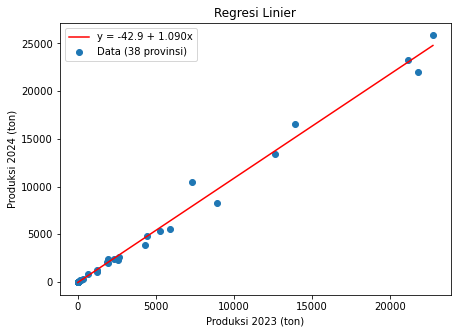

In [12]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, label='Data (38 provinsi)')
xx = np.linspace(0, X.max(), 100).reshape(-1,1)
plt.plot(xx, m_cl.predict(xx), color='red', label=f'y = {m_cl.intercept_:.1f} + {m_cl.coef_[0]:.3f}x')
plt.xlabel('Produksi 2023 (ton)'); plt.ylabel('Produksi 2024 (ton)'); plt.legend(); plt.title('Regresi Linier')
plt.savefig('regresi.png', dpi=130); plt.show()

In [13]:
# Pembanding: regresi berganda memakai 2020-2023 sebagai fitur
Xm = clean[['2020','2021','2022','2023']].values
loo_m = cross_val_predict(LinearRegression(), Xm, y, cv=LeaveOneOut())
evaluasi('LOO regresi berganda', y, loo_m)

LOO regresi berganda         R2=0.9808  MAE=   472.8 ton  RMSE=   953.9 ton  WAPE= 11.4%


## Prediksi contoh
Produksi 2024 jika 2023 tercatat 4.304 ton (angka NTT) dan 21.810 ton (angka Maluku).

In [14]:
contoh = pd.DataFrame({'2023': [4304.254, 21810.129]})
contoh['prediksi_2024'] = m_cl.predict(contoh[['2023']].values).round(0)
contoh

,2023,prediksi_2024
0,4304.254,4648.0
1,21810.129,23729.0
